<div>
    <span style ="font-size: 40px; font-weight: bold; color: #8EB944">
        Preparation
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        1. Import the data and libraries
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [1]:
import pandas as pd
import numpy as np
from IPython.display import clear_output
from datetime import datetime
import matplotlib.pyplot as plt

In [2]:
# import the cleaned sessions data
sessions = pd.read_pickle('../data/data_charge_prep.pkl')

# import the weather data
weather = pd.read_csv('../data/weather_burbank_airport.csv')

# import the additional weather data we sourced
weather_add = pd.read_csv('../data/additional_weather_data.csv')

<div>
    <span style ="font-size: 40px; font-weight: bold; color: #8EB944">
        Clean the weather data
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        1. Drop unnecessary columns
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [3]:
# Drop unnecessary columns from the weather dataset
weather.drop(['city','felt_temperature','windspeed','pressure','cloud_cover_description','cloud_cover'],inplace=True,axis=1)

# Drop unnecessary columns from the additional weather dataset
weather_add.drop(['name', 'feelslike', 'dew', 'humidity',
       'precipprob', 'preciptype', 'snow', 'snowdepth', 'windgust',
       'windspeed', 'winddir', 'sealevelpressure', 'cloudcover', 'visibility',
       'solarradiation', 'solarenergy', 'uvindex', 'severerisk', 'conditions',
       'icon', 'stations'],axis=1,inplace=True)

In [4]:
# Print the remaining columns
print(f'Remaining columns in the weather DataFrame: {[x for x in weather.columns]}')
print(f'Remaining columns in the additional weather DataFrame: {[x for x in weather_add.columns]}')

Remaining columns in the weather DataFrame: ['timestamp', 'temperature', 'precipitation']
Remaining columns in the additional weather DataFrame: ['datetime', 'temp', 'precip']


In [5]:
# Rename the columns so that they match
columns = {
    'datetime': 'timestamp',
    'temp': 'temperature',
    'precip': 'precipitation'
}
weather_add.rename(columns=columns,inplace=True)

<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        2. Convert the time data
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [6]:
# Convert the timestamp column in the weather data to the pandas datetime format
weather['timestamp'] = pd.to_datetime(weather['timestamp'])
weather_add['timestamp'] = pd.to_datetime(weather_add['timestamp'])

# Round the timestamp column to the nearest hour
weather['timestamp'] = weather.timestamp.dt.round('h')

In [7]:
# Drop duplicates from the weather dataframe
weather.drop_duplicates(subset=['timestamp'], keep='first', inplace=True)

<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        2. Merge both DataFrames
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [8]:
# Drop the duplicate rows from the weather DataFrame
cutoff_time = pd.to_datetime('2020-12-31 23:59:59')

# Identify rows where the timestamp is after the cutoff time
duplicate_rows = weather[weather['timestamp'] > cutoff_time].index

# Drop these rows
weather.drop(duplicate_rows,inplace=True)

In [9]:
# Merge the DataFrames
weather = pd.concat([weather,weather_add],ignore_index=True)
weather.drop_duplicates(subset=['timestamp'], keep='first', inplace=True)
display(weather)

,timestamp,temperature,precipitation
0,2018-01-01 09:00:00,9.0,0.0
1,2018-01-01 10:00:00,9.0,0.0
2,2018-01-01 11:00:00,9.0,0.0
3,2018-01-01 12:00:00,9.0,0.0
4,2018-01-01 13:00:00,8.0,0.0
...,...,...,...
32368,2021-09-14 19:00:00,23.2,0.0
32369,2021-09-14 20:00:00,21.6,0.0
32370,2021-09-14 21:00:00,21.6,0.0
32371,2021-09-14 22:00:00,19.9,0.0


<div>
    <span style ="font-size: 40px; font-weight: bold; color: #8EB944">
        Aggregation
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        1. Clean the sessions DataFrame
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [10]:
sessions

,Unnamed: 0,id,connectionTime,disconnectTime,doneChargingTime,kWhDelivered,sessionID,siteID,spaceID,stationID,timezone,userID,userInputs,endChargingTime,chargingDurationMin,blockingDurationMin
30794,1,5bc90cb9f9af8b0d7fe77cd3,2018-04-25 05:45:10+00:00,2018-04-25 16:56:16+00:00,2018-04-25 08:44:15+00:00,10.013,2_39_95_27_2018-04-25 13:45:09.617470,2,CA-319,2-39-95-27,America/Los_Angeles,NaN,NaN,2018-04-25 08:44:15+00:00,179.083333,492.016667
30795,2,5bc90cb9f9af8b0d7fe77cd4,2018-04-25 05:45:50+00:00,2018-04-25 15:04:45+00:00,2018-04-25 06:51:44+00:00,5.257,2_39_79_380_2018-04-25 13:45:49.962001,2,CA-489,2-39-79-380,America/Los_Angeles,NaN,NaN,2018-04-25 06:51:44+00:00,65.900000,493.016667
30796,3,5bc90cb9f9af8b0d7fe77cd5,2018-04-25 06:37:06+00:00,2018-04-25 15:55:34+00:00,2018-04-25 08:05:22+00:00,5.177,2_39_79_379_2018-04-25 14:37:06.460772,2,CA-327,2-39-79-379,America/Los_Angeles,NaN,NaN,2018-04-25 08:05:22+00:00,88.266667,470.200000
30797,4,5bc90cb9f9af8b0d7fe77cd6,2018-04-25 06:40:34+00:00,2018-04-25 15:03:12+00:00,2018-04-25 09:40:30+00:00,10.119,2_39_79_381_2018-04-25 14:40:33.638896,2,CA-490,2-39-79-381,America/Los_Angeles,NaN,NaN,2018-04-25 09:40:30+00:00,179.933333,322.700000
30798,5,5bc90cb9f9af8b0d7fe77cd7,2018-04-25 06:43:50+00:00,2018-04-25 17:17:30+00:00,2018-04-25 08:18:28+00:00,7.910,2_39_139_28_2018-04-25 14:43:49.647430,2,CA-303,2-39-139-28,America/Los_Angeles,NaN,NaN,2018-04-25 08:18:28+00:00,94.633333,539.033333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49116,3031,61550519f9af8b76960e169c,2021-09-13 14:33:07+00:00,2021-09-13 15:06:55+00:00,NaT,17.720,2_39_81_4550_2021-09-13 22:33:04.543952,2,11900388,2-39-81-4550,America/Los_Angeles,3905.0,"[{'WhPerMile': 300, 'kWhRequested': 30.0, 'mil...",2021-09-13 15:06:55+00:00,33.800000,0.000000
49117,3032,61550519f9af8b76960e169d,2021-09-13 15:11:12+00:00,2021-09-13 17:43:11+00:00,2021-09-13 16:13:35+00:00,2.018,2_39_91_437_2021-09-13 23:10:59.528292,2,CA-317,2-39-91-437,America/Los_Angeles,1082.0,"[{'WhPerMile': 290, 'kWhRequested': 5.8, 'mile...",2021-09-13 16:13:35+00:00,62.383333,89.600000
20177,5874,6155053bf9af8b76960e16d0,2021-09-13 17:08:16+00:00,2021-09-13 17:31:24+00:00,2021-09-13 17:31:19+00:00,1.253,1_1_179_783_2021-09-14 01:08:03.220292,1,AG-3F29,1-1-179-783,America/Los_Angeles,6023.0,"[{'WhPerMile': 310, 'kWhRequested': 15.5, 'mil...",2021-09-13 17:31:19+00:00,23.050000,0.083333
49118,3033,61550519f9af8b76960e169e,2021-09-13 17:52:37+00:00,2021-09-13 19:05:10+00:00,NaT,45.064,2_39_81_4550_2021-09-14 01:52:31.129163,2,11900388,2-39-81-4550,America/Los_Angeles,19055.0,"[{'WhPerMile': 286, 'kWhRequested': 28.6, 'mil...",2021-09-13 19:05:10+00:00,72.550000,0.000000


In [11]:
sessions.columns

Index(['Unnamed: 0', 'id', 'connectionTime', 'disconnectTime',
       'doneChargingTime', 'kWhDelivered', 'sessionID', 'siteID', 'spaceID',
       'stationID', 'timezone', 'userID', 'userInputs', 'endChargingTime',
       'chargingDurationMin', 'blockingDurationMin'],
      dtype='object')

In [12]:
# Drop columns from the main dataset
sessions.drop(['Unnamed: 0', 'id', 
       'doneChargingTime', 'kWhDelivered', 'sessionID', 'spaceID',
       'timezone', 'userID', 'userInputs', 'endChargingTime',
       'chargingDurationMin', 'blockingDurationMin'],inplace=True,axis=1)

# Print the remaining columns
print(f'Remaining columns in the sessions DataFrame: {[x for x in sessions.columns]}')

Remaining columns in the sessions DataFrame: ['connectionTime', 'disconnectTime', 'siteID', 'stationID']


In [13]:

# Strip timezone information without converting the timestamps to UTC, as they have been converted in the data cleaning already
sessions['connectionTime'] = pd.to_datetime(sessions['connectionTime'], errors='coerce').apply(
    lambda x: x.replace(tzinfo=None) if isinstance(x, datetime) else x
)
sessions['disconnectTime'] = pd.to_datetime(sessions['disconnectTime'], errors='coerce').apply(
    lambda x: x.replace(tzinfo=None) if isinstance(x, datetime) else x
)

In [14]:
sessions

,connectionTime,disconnectTime,siteID,stationID
30794,2018-04-25 05:45:10,2018-04-25 16:56:16,2,2-39-95-27
30795,2018-04-25 05:45:50,2018-04-25 15:04:45,2,2-39-79-380
30796,2018-04-25 06:37:06,2018-04-25 15:55:34,2,2-39-79-379
30797,2018-04-25 06:40:34,2018-04-25 15:03:12,2,2-39-79-381
30798,2018-04-25 06:43:50,2018-04-25 17:17:30,2,2-39-139-28
...,...,...,...,...
49116,2021-09-13 14:33:07,2021-09-13 15:06:55,2,2-39-81-4550
49117,2021-09-13 15:11:12,2021-09-13 17:43:11,2,2-39-91-437
20177,2021-09-13 17:08:16,2021-09-13 17:31:24,1,1-1-179-783
49118,2021-09-13 17:52:37,2021-09-13 19:05:10,2,2-39-81-4550


<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        2. Aggregate the time data
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [15]:
# Split the DataFrame according to the two sites
site1 = sessions[sessions['siteID']==1]
site2 = sessions[sessions['siteID']==2]

# Print the start and end of the timeframes
print(f'Site 1 Timespan: {site1.connectionTime.min()} - {site1.disconnectTime.max()}')
print(f'Site 2 Timespan: {site2.connectionTime.min()} - {site2.disconnectTime.max()}')

Site 1 Timespan: 2018-09-05 03:04:13 - 2021-09-14 06:46:28
Site 2 Timespan: 2018-04-25 05:45:10 - 2021-09-13 19:05:10


In [16]:
# Get the number of stations for each site
print(f'Number of stations for Site 1: {site1.stationID.nunique()}')
print(f'Number of stations for Site 2: {site2.stationID.nunique()}')

Number of stations for Site 1: 52
Number of stations for Site 2: 55


In [17]:
# Create a date range for all hours for the first site
date_range = pd.date_range(start='2018-09-05 03:00:00', end='2021-09-14 08:00:00', freq='h')

# Create the DataFrame
data_site1 = pd.DataFrame({
    'timestamp': date_range,
    # Create an empty column for the utilization
    'utilization': [float(0.0)] * len(date_range),
    'site': [1 for x in range(len(date_range))]
})

display(data_site1)

,timestamp,utilization,site
0,2018-09-05 03:00:00,0.0,1
1,2018-09-05 04:00:00,0.0,1
2,2018-09-05 05:00:00,0.0,1
3,2018-09-05 06:00:00,0.0,1
4,2018-09-05 07:00:00,0.0,1
...,...,...,...
26521,2021-09-14 04:00:00,0.0,1
26522,2021-09-14 05:00:00,0.0,1
26523,2021-09-14 06:00:00,0.0,1
26524,2021-09-14 07:00:00,0.0,1


In [18]:
# Define a function to calculate the utilization
def add_utilization(df: pd.DataFrame, start_time, end_time):
    # Find the index of the first hour that may overlap with the timespan
    start_idx = df.index[df['timestamp'] >= start_time][0]
    
    # Iterate only through relevant rows
    for i in range(start_idx, len(df)):
        row = df.iloc[i]
        hour_start = row['timestamp'] - pd.Timedelta(hours=1)
        hour_end = hour_start + pd.Timedelta(hours=1)

        # Stop checking if we are beyond the end_time
        if hour_start >= end_time:
            break

        # Check overlaps
        if hour_start >= start_time and hour_end <= end_time:
            # Fully within the timespan
            df.loc[i-1, 'utilization'] += 1
        elif start_time <= hour_start < end_time < hour_end:
            # Partial overlap (end time within this hour)
            overlap = round((end_time - hour_start).total_seconds() / 3600, 2)
            df.loc[i-1, 'utilization'] += overlap
        elif hour_start < start_time < hour_end:
            # Partial overlap (start time within this hour)
            overlap = round((hour_end - start_time).total_seconds() / 3600, 2)
            df.loc[i-1, 'utilization'] += overlap
            
    return None
    

In [19]:
for datapoint in range(len(site1)-1):
    
    start_time = site1.iloc[datapoint].connectionTime
    end_time = site1.iloc[datapoint].disconnectTime
    
    add_utilization(data_site1,start_time,end_time)
    
    if datapoint % 1000 == 0:
        print(f'Datapoint: {datapoint}')
        clear_output(wait=True)

Datapoint: 32000


In [20]:
# Create a date range for all hours in the specified year
date_range = pd.date_range(start='2018-04-25 04:00:00', end='2021-09-13 20:00:00', freq='h')

# Create the DataFrame
data_site2 = pd.DataFrame({
    'timestamp': date_range,
    # Create an empty column for the utilization
    'utilization': [float(0.0)] * len(date_range),
    'site': [2 for x in range(len(date_range))]
})


In [21]:
for datapoint in range(len(site2)-1):
    
    start_time = site2.iloc[datapoint].connectionTime
    end_time = site2.iloc[datapoint].disconnectTime
    
    add_utilization(data_site2,start_time,end_time)
    
    if datapoint % 1000 == 0:
        print(f'Datapoint: {datapoint}')
        clear_output(wait=True)

Datapoint: 31000


In [22]:
display(data_site1)
display(data_site2)

,timestamp,utilization,site
0,2018-09-05 03:00:00,1.79,1
1,2018-09-05 04:00:00,2.55,1
2,2018-09-05 05:00:00,7.83,1
3,2018-09-05 06:00:00,14.57,1
4,2018-09-05 07:00:00,15.00,1
...,...,...,...
26521,2021-09-14 04:00:00,0.00,1
26522,2021-09-14 05:00:00,0.00,1
26523,2021-09-14 06:00:00,0.00,1
26524,2021-09-14 07:00:00,0.00,1


,timestamp,utilization,site
0,2018-04-25 04:00:00,0.00,2
1,2018-04-25 05:00:00,0.49,2
2,2018-04-25 06:00:00,3.20,2
3,2018-04-25 07:00:00,13.70,2
4,2018-04-25 08:00:00,27.83,2
...,...,...,...
29700,2021-09-13 16:00:00,8.60,2
29701,2021-09-13 17:00:00,4.53,2
29702,2021-09-13 18:00:00,0.37,2
29703,2021-09-13 19:00:00,0.00,2


In [23]:
# Calculate the utilization in percent
data_site1['utilization2'] = round(data_site1['utilization']/52,2)
data_site2['utilization2'] = round(data_site2['utilization']/55,2)

In [24]:
# Merge the DataFrames
utilization = pd.concat([data_site1,data_site2],ignore_index=True)

In [25]:
# Rename the columns in the DataFrames
columns = {
    'timestamp': 'timestamp',
    'utilization': 'utilization_absolute',
    'site': 'site',
    'utilization2': 'utilization_perc'
}
utilization.rename(columns=columns, inplace=True)

In [26]:
utilization

,timestamp,utilization_absolute,site,utilization_perc
0,2018-09-05 03:00:00,1.79,1,0.03
1,2018-09-05 04:00:00,2.55,1,0.05
2,2018-09-05 05:00:00,7.83,1,0.15
3,2018-09-05 06:00:00,14.57,1,0.28
4,2018-09-05 07:00:00,15.00,1,0.29
...,...,...,...,...
56226,2021-09-13 16:00:00,8.60,2,0.16
56227,2021-09-13 17:00:00,4.53,2,0.08
56228,2021-09-13 18:00:00,0.37,2,0.01
56229,2021-09-13 19:00:00,0.00,2,0.00


<div>
    <span style ="font-size: 40px; font-weight: bold; color: #8EB944">
        Merger of Weather and Sessions Data
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        1. Add the weather data to the DataFrame
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [27]:
# Merge the weather DataFrame and the utilization DataFrame to get the final DataFrame 
utilization_final = pd.merge(utilization,weather, on='timestamp', how='left')

In [28]:
display(utilization_final)

,timestamp,utilization_absolute,site,utilization_perc,temperature,precipitation
0,2018-09-05 03:00:00,1.79,1,0.03,18.0,0.0
1,2018-09-05 04:00:00,2.55,1,0.05,18.0,0.0
2,2018-09-05 05:00:00,7.83,1,0.15,18.0,0.0
3,2018-09-05 06:00:00,14.57,1,0.28,18.0,0.0
4,2018-09-05 07:00:00,15.00,1,0.29,18.0,0.0
...,...,...,...,...,...,...
56226,2021-09-13 16:00:00,8.60,2,0.16,33.2,0.0
56227,2021-09-13 17:00:00,4.53,2,0.08,31.8,0.0
56228,2021-09-13 18:00:00,0.37,2,0.01,29.8,0.0
56229,2021-09-13 19:00:00,0.00,2,0.00,27.0,0.0


<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        2. Check for missing values
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [29]:
# Check for rows with misssing data
utilization_final[utilization_final['temperature'].isna()]

,timestamp,utilization_absolute,site,utilization_perc,temperature,precipitation
1010,2018-10-17 05:00:00,9.17,1,0.18,NaN,NaN
1764,2018-11-17 15:00:00,2.87,1,0.06,NaN,0.0
2144,2018-12-03 11:00:00,49.11,1,0.94,NaN,NaN
5552,2019-04-24 11:00:00,48.75,1,0.94,NaN,NaN
6389,2019-05-29 08:00:00,51.00,1,0.98,NaN,NaN
...,...,...,...,...,...,...
49074,2020-11-19 16:00:00,2.00,2,0.04,NaN,0.0
49520,2020-12-08 06:00:00,0.00,2,0.00,NaN,NaN
49521,2020-12-08 07:00:00,0.00,2,0.00,NaN,NaN
50026,2020-12-29 08:00:00,0.00,2,0.00,NaN,0.0


In [30]:
# Drop the affected rows
idx = utilization_final[utilization_final.isna().any(axis=1)].index

utilization_final.drop(idx,inplace=True)

In [31]:
utilization_final

,timestamp,utilization_absolute,site,utilization_perc,temperature,precipitation
0,2018-09-05 03:00:00,1.79,1,0.03,18.0,0.0
1,2018-09-05 04:00:00,2.55,1,0.05,18.0,0.0
2,2018-09-05 05:00:00,7.83,1,0.15,18.0,0.0
3,2018-09-05 06:00:00,14.57,1,0.28,18.0,0.0
4,2018-09-05 07:00:00,15.00,1,0.29,18.0,0.0
...,...,...,...,...,...,...
56226,2021-09-13 16:00:00,8.60,2,0.16,33.2,0.0
56227,2021-09-13 17:00:00,4.53,2,0.08,31.8,0.0
56228,2021-09-13 18:00:00,0.37,2,0.01,29.8,0.0
56229,2021-09-13 19:00:00,0.00,2,0.00,27.0,0.0


<div>
    <span style ="font-size: 40px; font-weight: bold; color: #8EB944">
        Feature Engineering
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        1. Add a feature for the seasons
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [32]:
# Create a new column for seasons based on the 'timestamp' column
utilization_final['winter'] = utilization_final['timestamp'].dt.month.isin([12, 1, 2]).astype(int)
utilization_final['autumn'] = utilization_final['timestamp'].dt.month.isin([9, 10, 11]).astype(int)
utilization_final['summer'] = utilization_final['timestamp'].dt.month.isin([6, 7, 8]).astype(int)

In [33]:
utilization_final

,timestamp,utilization_absolute,site,utilization_perc,temperature,precipitation,winter,autumn,summer
0,2018-09-05 03:00:00,1.79,1,0.03,18.0,0.0,0,1,0
1,2018-09-05 04:00:00,2.55,1,0.05,18.0,0.0,0,1,0
2,2018-09-05 05:00:00,7.83,1,0.15,18.0,0.0,0,1,0
3,2018-09-05 06:00:00,14.57,1,0.28,18.0,0.0,0,1,0
4,2018-09-05 07:00:00,15.00,1,0.29,18.0,0.0,0,1,0
...,...,...,...,...,...,...,...,...,...
56226,2021-09-13 16:00:00,8.60,2,0.16,33.2,0.0,0,1,0
56227,2021-09-13 17:00:00,4.53,2,0.08,31.8,0.0,0,1,0
56228,2021-09-13 18:00:00,0.37,2,0.01,29.8,0.0,0,1,0
56229,2021-09-13 19:00:00,0.00,2,0.00,27.0,0.0,0,1,0


<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        2. Add a feature for the lockdown
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

<p style="font-size: 15px;">The dataset includes the impact of the pandemic on charging behaviour. We included the 2020 lockdown in our model.  This information has been incorporated into our model. The information about the lockdown was sourced <a href="https://pmc.ncbi.nlm.nih.gov/articles/PMC7996058/">from this website</a>.</p>

In [34]:
# Define the start and end time of the lockdown in California from the soruce above
start_time = pd.to_datetime('2020-03-19 00:00:00')
end_time = pd.to_datetime('2021-01-25 00:00:00')

# Create the new column with 1 if within the timespan, 0 otherwise
utilization_final['stay_at_home'] = ((utilization_final['timestamp'] >= start_time) & (utilization_final['timestamp'] <= end_time)).astype(int)

<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        3. Add a feature for the holidays
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

<p style="font-size: 15px;">It is less common for people to charge their vehicles during holiday periods. As there are no legally binding holidays in the USA, we have included federal holidays, as these are observed by the majority of private businesses. The information about the holidays was sourced <a href="https://leaveboard.com/public-holidays/united-states-california-public-holidays-2018/" target="_blank">from this website</a>.</p>

In [35]:
# Create a list for each holiday in the time period
holidays_str = [
    '2018-01-01','2018-01-15', '2018-02-19','2018-03-31','2018-05-28','2018-07-04',
    '2018-09-03','2018-10-08','2018-11-12','2018-11-22','2018-11-23','2018-12-25',
    '2019-01-01','2019-01-21', '2019-02-18','2019-04-01','2019-05-27','2019-07-04',
    '2019-09-02','2019-11-11','2019-11-28','2019-11-29','2019-12-25',
    '2020-01-01','2020-01-20', '2020-02-17','2020-03-31','2020-05-25','2020-07-04',
    '2020-09-07','2020-11-11','2020-11-26','2020-11-27','2020-12-25',
    '2021-01-01','2021-01-18', '2021-02-15','2021-03-31','2021-05-31','2021-07-05',
    '2021-09-06','2021-11-11','2021-11-25','2021-11-26','2021-12-25',
]

# Convert the strings to the pandas datetime format
holidays = [pd.to_datetime(x).date() for x in holidays_str]

In [36]:
# Create a new column that is 1 if the timestamp is in any of the specific days, 0 otherwise
utilization_final['holiday'] = utilization_final['timestamp'].dt.date.isin(holidays).astype(int)

display(utilization_final)

,timestamp,utilization_absolute,site,utilization_perc,temperature,precipitation,winter,autumn,summer,stay_at_home,holiday
0,2018-09-05 03:00:00,1.79,1,0.03,18.0,0.0,0,1,0,0,0
1,2018-09-05 04:00:00,2.55,1,0.05,18.0,0.0,0,1,0,0,0
2,2018-09-05 05:00:00,7.83,1,0.15,18.0,0.0,0,1,0,0,0
3,2018-09-05 06:00:00,14.57,1,0.28,18.0,0.0,0,1,0,0,0
4,2018-09-05 07:00:00,15.00,1,0.29,18.0,0.0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
56226,2021-09-13 16:00:00,8.60,2,0.16,33.2,0.0,0,1,0,0,0
56227,2021-09-13 17:00:00,4.53,2,0.08,31.8,0.0,0,1,0,0,0
56228,2021-09-13 18:00:00,0.37,2,0.01,29.8,0.0,0,1,0,0,0
56229,2021-09-13 19:00:00,0.00,2,0.00,27.0,0.0,0,1,0,0,0


<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        4. Add a time related features
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [37]:
# Add a binary variable for the weekend
utilization_final['weekend'] = utilization_final['timestamp'].apply(lambda x: 1 if x.weekday() in [5,6] else 0)

# Add a binary variable for fridays 
utilization_final['friday'] = utilization_final['timestamp'].apply(lambda x: 1 if x.weekday() == 4 else 0)

# Add a variable for the hour
utilization_final['hour'] = utilization_final['timestamp'].dt.hour

In [38]:
utilization_final

,timestamp,utilization_absolute,site,utilization_perc,temperature,precipitation,winter,autumn,summer,stay_at_home,holiday,weekend,friday,hour
0,2018-09-05 03:00:00,1.79,1,0.03,18.0,0.0,0,1,0,0,0,0,0,3
1,2018-09-05 04:00:00,2.55,1,0.05,18.0,0.0,0,1,0,0,0,0,0,4
2,2018-09-05 05:00:00,7.83,1,0.15,18.0,0.0,0,1,0,0,0,0,0,5
3,2018-09-05 06:00:00,14.57,1,0.28,18.0,0.0,0,1,0,0,0,0,0,6
4,2018-09-05 07:00:00,15.00,1,0.29,18.0,0.0,0,1,0,0,0,0,0,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56226,2021-09-13 16:00:00,8.60,2,0.16,33.2,0.0,0,1,0,0,0,0,0,16
56227,2021-09-13 17:00:00,4.53,2,0.08,31.8,0.0,0,1,0,0,0,0,0,17
56228,2021-09-13 18:00:00,0.37,2,0.01,29.8,0.0,0,1,0,0,0,0,0,18
56229,2021-09-13 19:00:00,0.00,2,0.00,27.0,0.0,0,1,0,0,0,0,0,19


<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        5. Additional features
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [39]:
# Change the site column to be binary
utilization_final['site_01'] = utilization_final['site'].apply(lambda x: 1 if x == 1 else 0)

# Drop the old column
utilization_final.drop(['site'],axis=1,inplace=True)

In [40]:
# Add a additional variable for the weekday
utilization_final['weekday'] = utilization_final.timestamp.apply(lambda x: x.weekday())

# Add a additional variable for the month
utilization_final['month'] = utilization_final.timestamp.apply(lambda x: x.month)

In [41]:
# Add a sine and cosine variable to the DataFrame for all cyclical variables
utilization_final['hour_sin'] = np.sin(2 * np.pi * utilization_final['hour'] / 24)
utilization_final['hour_cos'] = np.cos(2 * np.pi * utilization_final['hour'] / 24)
utilization_final['weekday_sin'] = np.sin(2* np.pi * utilization_final['weekday'] / 7)
utilization_final['weekday_cos'] = np.cos(2 * np.pi * utilization_final['weekday'] / 7)
utilization_final['month_sin'] = np.sin(2 * np.pi * utilization_final['month'] / 12)
utilization_final['month_cos'] = np.cos(2 * np.pi * utilization_final['month'] / 12)

In [42]:
# Sort the final DataFrame based on the timestamps
utilization_final.sort_values('timestamp').reset_index(drop=True,inplace=True)


<div>
    <span style ="font-size: 40px; font-weight: bold; color: #8EB944">
        Fill data gaps 
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

In [43]:
# Function to find gaps of at least 49 consecutive timestamps with 0 utilization
# more than 2 entire days (more than a weekend)
def find_gaps(df):
    # Create a mask for zero utilization
    zero_mask = df['utilization_perc'] == 0
    
    # Initialize variables
    gaps = []
    start_idx = None
    
    # Iterate through the data
    for i in range(len(df)):
        if zero_mask.iloc[i]:
            if start_idx is None:
                start_idx = i
        else:
            if start_idx is not None:
                # Check if gap is at least 49 timestamps
                if i - start_idx >= 49:
                    gaps.append({
                        'start': df['timestamp'].iloc[start_idx],
                        'end': df['timestamp'].iloc[i-1],
                        'duration_hours': i - start_idx
                    })
                start_idx = None
    
    # Check for gap at the end of the dataset
    if start_idx is not None and len(df) - start_idx >= 49:
        gaps.append({
            'start': df['timestamp'].iloc[start_idx],
            'end': df['timestamp'].iloc[-1],
            'duration_hours': len(df) - start_idx
        })
    
    return gaps

In [44]:
# Define a helper function to fill specified gaps 
def fill_gaps_with_trend(period_df, is_post_covid):
    if len(period_df) == 0:
        return period_df

    # Ensure working with a copy 
    period_df = period_df.copy()
    
    period_df['hour'] = period_df['timestamp'].dt.hour
    period_df['day_of_week'] = period_df['timestamp'].dt.dayofweek

    # find the typical (median) values for a given hour and day (only consider the data outside of the gaps ofc) 
    pattern_matrix = period_df[period_df.in_gap==False].groupby(['hour', 'day_of_week'])['utilization_perc'].median()

    # For rows within gaps, assign the typical pattern value 
    for idx in period_df.index:
        if period_df.loc[idx, 'in_gap']:
            ts = period_df.loc[idx, 'timestamp']
            typical = pattern_matrix.get((ts.hour, ts.day_of_week), np.nan)
                
            period_df.loc[idx, 'utilization_perc'] = typical
    return period_df


In [45]:
def covid_aware_pattern_fill(data):
    data_copy = data.copy()
    data_copy['timestamp'] = pd.to_datetime(data_copy['timestamp'])
    data_copy = data_copy.sort_values('timestamp')  # ensure time-ordered

    covid_break = pd.Timestamp('2020-03-18')

    result_list = []

    # Process each site separately
    for site in data_copy['site_01'].unique():
        site_data = data_copy[data_copy['site_01'] == site].copy()

        # find gaps for each site
        gaps = find_gaps(site_data)
        
        # Add a column to mark if a row is within a specified gap
        site_data['in_gap'] = False
        for gap in gaps:
            start, end = gap['start'], gap['end']
            site_data.loc[(site_data['timestamp'] >= start) & (site_data['timestamp'] <= end), 'in_gap'] = True

        # Split pre/post COVID with Boolean masks
        pre_mask = site_data['timestamp'] < covid_break
        post_mask = site_data['timestamp'] >= covid_break

        # Fill for pre-COVID block, then post-COVID 
        pre_filled = fill_gaps_with_trend(site_data[pre_mask], is_post_covid=False)
        post_filled = fill_gaps_with_trend(site_data[post_mask], is_post_covid=True)

        # Combine them back
        combined = pd.concat([pre_filled, post_filled])
        result_list.append(combined)

    # Build the final result
    filled_df = pd.concat(result_list)
    # Sort by time again
    filled_df = filled_df.sort_values('timestamp')

    return filled_df

In [46]:
# Apply function to the utilization dataframe
filled_df = covid_aware_pattern_fill(utilization_final)



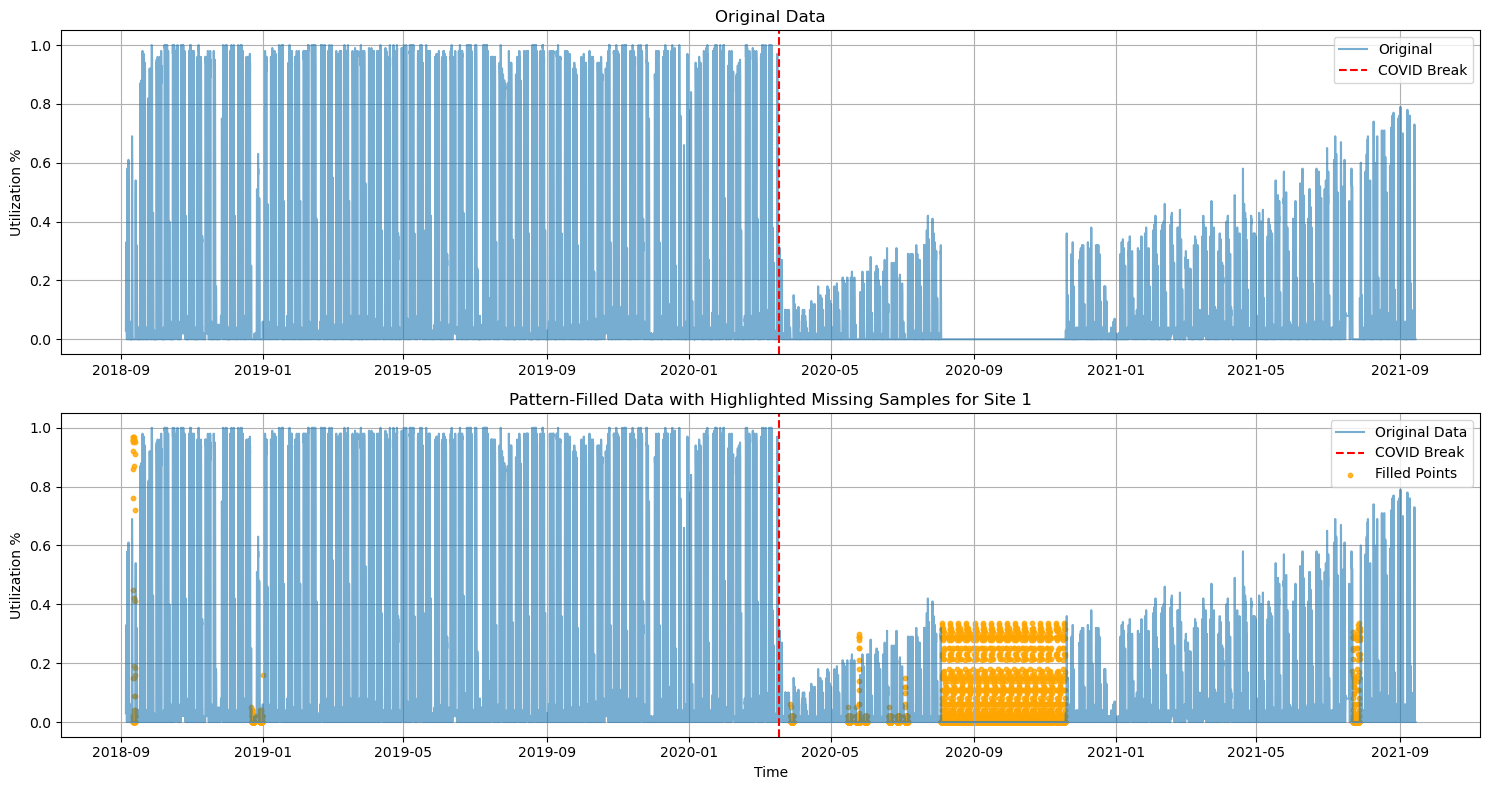

In [47]:
# Highlight missing samples that were filled in the plot  for site 1
plt.figure(figsize=(15, 8))


# Plot original data
plt.subplot(2, 1, 1)
plt.plot(utilization_final[utilization_final.site_01 == 1]['timestamp'], utilization_final[utilization_final.site_01 == 1]['utilization_perc'], label='Original', alpha=0.6)
plt.axvline(x=pd.Timestamp('2020-03-18'), color='r', linestyle='--', label='COVID Break')
plt.title('Original Data')
plt.ylabel('Utilization %')
plt.legend()
plt.grid(True)

# Plot filled data
plt.subplot(2, 1, 2)
# Original data plot
plt.plot(utilization_final[utilization_final.site_01 == 1]['timestamp'], utilization_final[utilization_final.site_01 == 1]['utilization_perc'], label='Original Data', alpha=0.6)
plt.axvline(x=pd.Timestamp('2020-03-18'), color='r', linestyle='--', label='COVID Break')

# Highlight filled points
filled_df_site1 = filled_df[filled_df.site_01 == 1]
filled_points = filled_df_site1.loc[filled_df_site1.in_gap == True]
plt.scatter(filled_points['timestamp'], filled_points['utilization_perc'], 
            color='orange', label='Filled Points', s=10, alpha=0.8)

# Add labels and legend
plt.title('Pattern-Filled Data with Highlighted Missing Samples for Site 1')
plt.xlabel('Time')
plt.ylabel('Utilization %')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

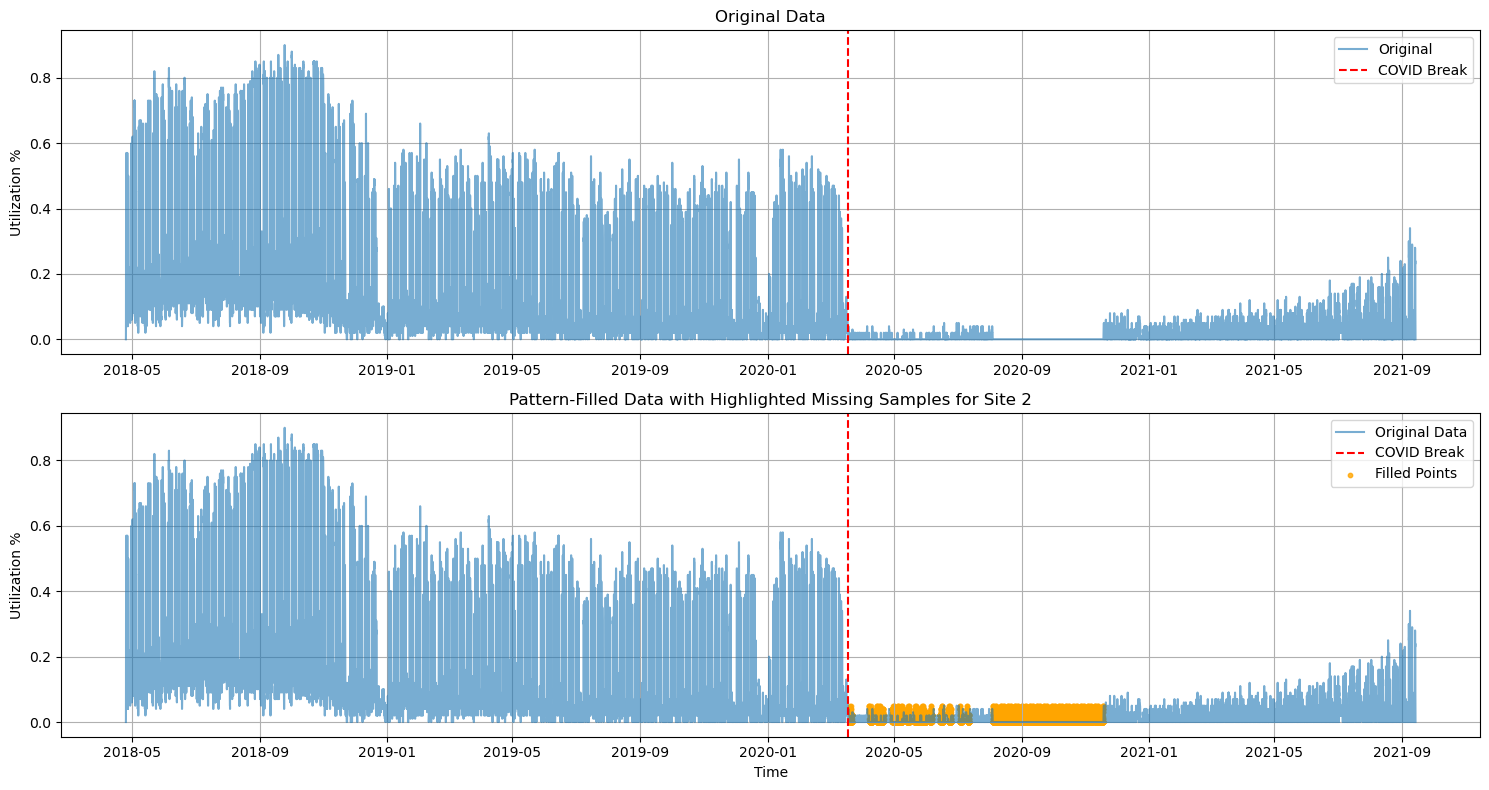

In [48]:
# Highlight missing samples that were filled in the plot for site 2
plt.figure(figsize=(15, 8))


# Plot original data
plt.subplot(2, 1, 1)
plt.plot(utilization_final[utilization_final.site_01 == 0]['timestamp'], utilization_final[utilization_final.site_01 == 0]['utilization_perc'], label='Original', alpha=0.6)
plt.axvline(x=pd.Timestamp('2020-03-18'), color='r', linestyle='--', label='COVID Break')
plt.title('Original Data')
plt.ylabel('Utilization %')
plt.legend()
plt.grid(True)

# Plot filled data
plt.subplot(2, 1, 2)
# Original data plot
plt.plot(utilization_final[utilization_final.site_01 == 0]['timestamp'], utilization_final[utilization_final.site_01 == 0]['utilization_perc'], label='Original Data', alpha=0.6)
plt.axvline(x=pd.Timestamp('2020-03-18'), color='r', linestyle='--', label='COVID Break')

# Highlight filled points
filled_df_site2 = filled_df[filled_df.site_01 == 0]
filled_points = filled_df_site2.loc[filled_df_site2.in_gap == True]
plt.scatter(filled_points['timestamp'], filled_points['utilization_perc'], 
            color='orange', label='Filled Points', s=10, alpha=0.8)

# Add labels and legend
plt.title('Pattern-Filled Data with Highlighted Missing Samples for Site 2')
plt.xlabel('Time')
plt.ylabel('Utilization %')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [49]:
def plot_subseries(data, start_date, end_date):
    # Ensure the index is a DatetimeIndex
    data = data.set_index('timestamp') if 'timestamp' in data.columns else data
    data.index = pd.to_datetime(data.index)  # Convert index to DatetimeIndex if not already
    
    # Slice the subset
    subset = data.loc[start_date:end_date]
    
    
    plt.figure(figsize=(12, 9))
    
    plt.subplot(411)
    plt.plot(subset.utilization_perc)
    
    plt.tight_layout()
    plt.show()

## Visualize the filled timeseries

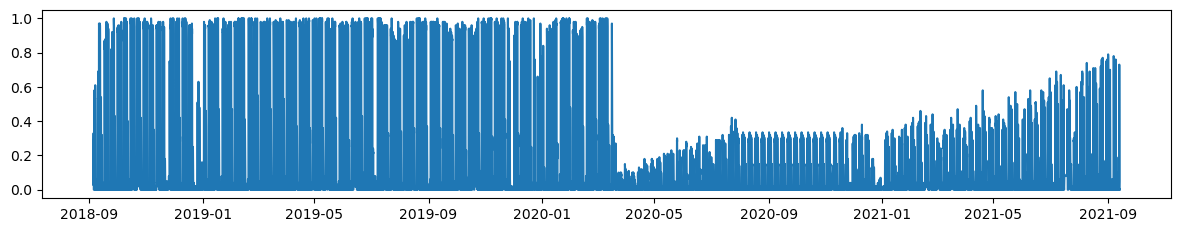

In [50]:
# Site 1
plot_subseries(filled_df[filled_df.site_01==1], "2018-04-15", "2021-09-13")

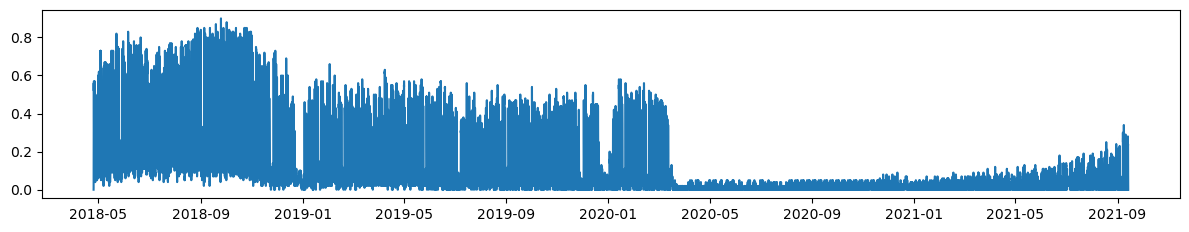

In [51]:
# Site 2
plot_subseries(filled_df[filled_df.site_01==0], "2018-04-15", "2021-09-13")


<div>
    <span style ="font-size: 40px; font-weight: bold; color: #8EB944">
        (Optional) Export
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

In [52]:
filled_df.to_csv('utilization_final.csv',index=False)